# 第8章：测试集过拟合——最大夏普、PSR与DSR

## 统一实验约定
各章节在项目根目录独立运行，无需安装本项目。公共数据处理与实验辅助见 [notebook_common.py](notebook_common.py)，依赖集中在 [requirement.txt](requirement.txt)。

所有章节读取 `data/hs_funds_prices.parquet`，固定种子42。最近1,260个价格观测中，前1,008个用于训练，后252个用于测试。
`SelectComplete` 排除训练收益中的全部缺失；`DropZeroVariance` 的阈值换算后保持原口径：样本方差（`ddof=1`）大于 `1e-12`。默认使用全部合格基金，测试期不重新筛选资产。
先计算单日收益，再排除共同无效日期，不做填充。测试结果**不是连续、可交易的回测**；价格复权口径尚未确认。

初始化只展示数据摘要；完整资产和排除日期可按需查看 `data.assets`、`data.excluded_test_dates`。`ML4AM_SMOKE=1` 仅供自动化小样本验证，正常运行不设置。

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from time import perf_counter
from notebook_common import load_data, setup_notebook

SEED = 42
setup_notebook(SEED)
data = load_data()
X_train, X_test, assets = data.X_train, data.X_test, data.assets
display(data.summary())

数据模式                          全部合格基金
训练期合格基金数                         488
本次使用基金数                          488
训练收益行数                          1007
训练收益区间       2021-07-14 至 2025-09-04
测试候选区间       2025-09-05 至 2026-09-18
测试候选日期数                          252
测试共同有效日期数                        124
排除测试日期数                          128
测试日期覆盖率                       49.21%
Name: 数据概览, dtype: object

## 1. 最大夏普期望公式
[原脚本](Machine_Learning_for_Asset_Managers/ch8_testing_set_overfitting.py)无条件导入未使用的cupy，
本章不导入整个模块，局部逐式复现相关公式。原Euler–Mascheroni常数写成0.477…，
正确值约0.577…；原样、纠正公式与skfolio三列分别展示，不把修正藏在兼容层。
极值近似假设试验夏普独立且近似正态，有限试验数量时不是精确等式。

,原常数公式,纠正常数公式,skfolio
试验数,,,
2,0.429710,0.519755,0.519755
5,1.131790,1.192594,1.192594
10,1.523829,1.574598,1.574598
50,2.237747,2.276303,2.276303
100,2.495217,2.530603,2.530603
1000,3.226555,3.255122,3.255122


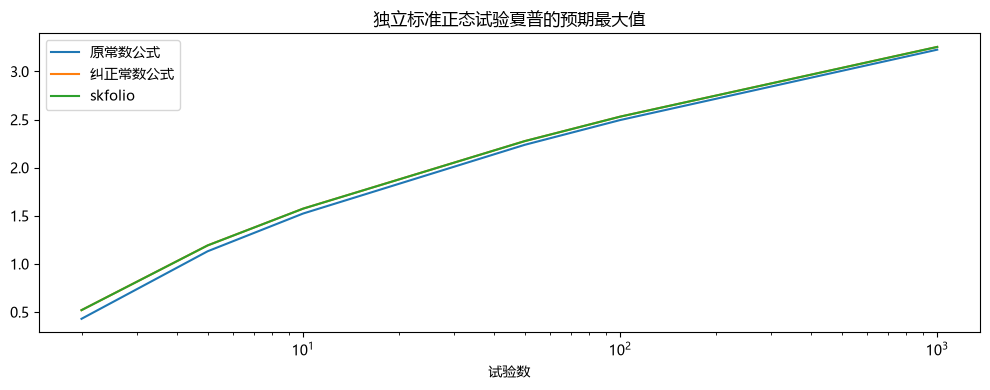

In [2]:
from scipy.stats import norm
from skfolio.measures import expected_max_sharpe_ratio, probabilistic_sharpe_ratio, deflated_sharpe_ratio
from skfolio.optimization import MeanRisk
from skfolio.moments import EmpiricalCovariance, LedoitWolf, DenoiseCovariance
from skfolio.prior import EmpiricalPrior

def original_expected_max(n_trials, mean_sr=0., std_sr=1., gamma=.47721566490153286):
    return mean_sr + std_sr*((1-gamma)*norm.ppf(1-1/n_trials) + gamma*norm.ppf(1-1/(n_trials*np.e)))
trial_counts = [2, 5, 10, 50, 100, 1000]
formula_table = pd.DataFrame({'试验数': trial_counts,
    '原常数公式': [original_expected_max(n) for n in trial_counts],
    '纠正常数公式': [original_expected_max(n, gamma=np.euler_gamma) for n in trial_counts],
    'skfolio': [expected_max_sharpe_ratio(n, 1.) for n in trial_counts]}).set_index('试验数')
display(formula_table)
np.testing.assert_allclose(formula_table['纠正常数公式'], formula_table['skfolio'], atol=1e-12)
formula_table.plot(logx=True, title='独立标准正态试验夏普的预期最大值')
plt.tight_layout(); plt.show()

## 2. 同一数据上的9个真实策略试验
训练期拟合，共同有效测试日期计算日收益。固定网格为3种协方差估计器×3种long-only上限，
不根据结果增删模型。每个尝试都记录，失败不冒充收益为零。
全部模型统一使用第7章验证的目标尺度 `1e4` 与CLARABEL容差 `1e-12`；
这是数值精度配置，不是依据测试夏普搜索的额外超参数。
`optimal_inaccurate`单独列出，表示返回了满足权重检查的近似解，不保证达到所设全部数值容差。
演示故意在这份测试结果上选优，以说明选择偏差；它不是选优后的独立验证集。

In [3]:
trial_records, trial_returns = [], {}
SOLVER_OPTIONS = {'scale_objective': 1e4, 'save_problem': True, 'solver_params':
                  {'tol_gap_abs': 1e-12, 'tol_gap_rel': 1e-12, 'tol_feas': 1e-12}}
for estimator_name, estimator_class in [('Empirical', EmpiricalCovariance), ('LedoitWolf', LedoitWolf), ('Denoise', DenoiseCovariance)]:
    for cap in [.05, .10, 1.0]:
        name = f'{estimator_name}/max_weight={cap}'
        start = perf_counter()
        record = {'试验': name, '状态': '失败', '非年化夏普': np.nan, '错误': ''}
        print('开始试验：', name, flush=True)
        try:
            model = MeanRisk(min_weights=0., max_weights=cap, **SOLVER_OPTIONS,
                prior_estimator=EmpiricalPrior(covariance_estimator=estimator_class())).fit(X_train)
            w = np.asarray(model.weights_)
            if not np.isfinite(w).all() or not np.isclose(w.sum(), 1., atol=1e-5):
                raise ValueError('无效权重')
            if w.min() < -1e-5 or w.max() > cap+1e-5:
                raise ValueError('权重边界超出容差')
            values = X_test.to_numpy() @ w
            if not np.isfinite(values).all() or values.std(ddof=1) <= 0:
                raise ValueError('收益无效或零波动')
            trial_returns[name] = values
            record.update({'状态': '成功', '求解状态': model.problem_.status,
                                       '非年化夏普': values.mean()/values.std(ddof=1)})
        except Exception as exc:
            record['错误'] = f'{type(exc).__name__}: {exc}'
        record['耗时秒'] = perf_counter()-start
        trial_records.append(record)
        print('结束试验：', name, record['状态'], flush=True)
trials = pd.DataFrame(trial_records).set_index('试验')
display(trials)
assert len(trials) == 9

开始试验： Empirical/max_weight=0.05


结束试验： Empirical/max_weight=0.05 成功


开始试验： Empirical/max_weight=0.1


结束试验： Empirical/max_weight=0.1 成功


开始试验： Empirical/max_weight=1.0


...

开始试验： Denoise/max_weight=0.1


结束试验： Denoise/max_weight=0.1 成功


开始试验： Denoise/max_weight=1.0


结束试验： Denoise/max_weight=1.0 成功


,状态,非年化夏普,错误,求解状态,耗时秒
试验,,,,,
Empirical/max_weight=0.05,成功,0.156139,,optimal,0.661665
Empirical/max_weight=0.1,成功,-0.039610,,optimal,0.676794
Empirical/max_weight=1.0,成功,0.022081,,optimal,0.888597
LedoitWolf/max_weight=0.05,成功,0.166312,,optimal,0.688005
LedoitWolf/max_weight=0.1,成功,0.153372,,optimal,0.717243
LedoitWolf/max_weight=1.0,成功,0.153372,,optimal,0.834273
Denoise/max_weight=0.05,成功,0.169082,,optimal,0.727434
Denoise/max_weight=0.1,成功,-0.045624,,optimal,0.858464
Denoise/max_weight=1.0,成功,0.020340,,optimal,0.909963


## 3. PSR与DSR
PSR将单一策略夏普与给定基准比较；DSR的基准来自全部试验夏普的离散度和数量。
输入均为相同周期的非年化量，无风险利率0。以下函数返回概率型统计量，不是调整后的年化夏普。
若任何试验失败，则完整9试验DSR不报告，避免悄悄低估试验次数。

在测试结果上选出的优胜试验： Denoise/max_weight=0.05 PSR： 0.9594870550244956
完整9试验DSR： 0.613838759854132 选择偏差基准夏普： 0.1410429126042076


,Empirical/max_weight=0.05,Empirical/max_weight=0.1,Empirical/max_weight=1.0,LedoitWolf/max_weight=0.05,LedoitWolf/max_weight=0.1,LedoitWolf/max_weight=1.0,Denoise/max_weight=0.05,Denoise/max_weight=0.1,Denoise/max_weight=1.0
Empirical/max_weight=0.05,1.000000,0.483207,0.158088,0.976338,0.977028,0.977028,0.991249,0.479793,0.168587
Empirical/max_weight=0.1,0.483207,1.000000,0.246942,0.449751,0.540536,0.540536,0.449238,0.999639,0.181238
Empirical/max_weight=1.0,0.158088,0.246942,1.000000,0.159164,0.180464,0.180464,0.143757,0.246130,0.966854
LedoitWolf/max_weight=0.05,0.976338,0.449751,0.159164,1.000000,0.994459,0.994459,0.984388,0.445354,0.184072
LedoitWolf/max_weight=0.1,0.977028,0.540536,0.180464,0.994459,1.000000,1.000000,0.980135,0.536371,0.195435
LedoitWolf/max_weight=1.0,0.977028,0.540536,0.180464,0.994459,1.000000,1.000000,0.980135,0.536371,0.195435
Denoise/max_weight=0.05,0.991249,0.449238,0.143757,0.984388,0.980135,0.980135,1.000000,0.447180,0.165530
Denoise/max_weight=0.1,0.479793,0.999639,0.246130,0.445354,0.536371,0.536371,0.447180,1.000000,0.181349
Denoise/max_weight=1.0,0.168587,0.181238,0.966854,0.184072,0.195435,0.195435,0.165530,0.181349,1.000000


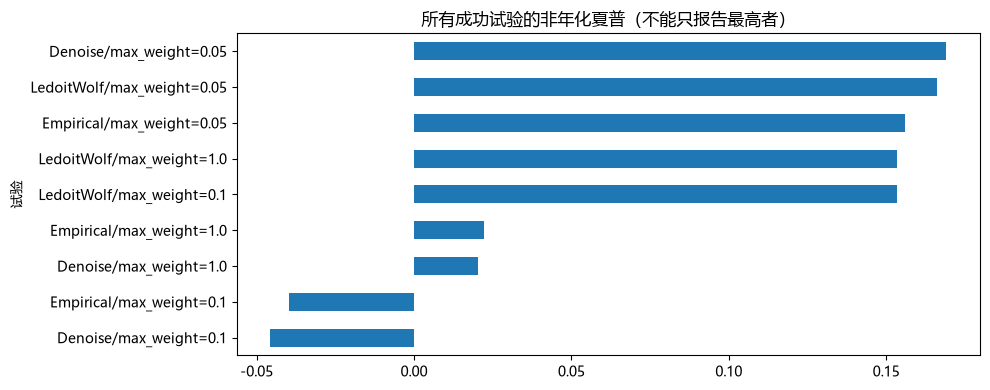

In [4]:
success = trials.loc[trials['状态'].eq('成功')]
if not success.empty:
    winner = success['非年化夏普'].idxmax()
    winner_returns = np.asarray(trial_returns[winner])
    psr = probabilistic_sharpe_ratio(winner_returns, benchmark_sharpe_ratio=0., risk_free_rate=0.)
    print('在测试结果上选出的优胜试验：', winner, 'PSR：', psr)
    if len(success) == len(trials):
        sr_values = success['非年化夏普'].to_numpy()
        dsr = deflated_sharpe_ratio(winner_returns, trial_sharpe_ratios=sr_values, risk_free_rate=0.)
        benchmark = expected_max_sharpe_ratio(len(sr_values), sr_values.std(ddof=1))
        print('完整9试验DSR：', dsr, '选择偏差基准夏普：', benchmark)
        assert 0 <= dsr <= 1 and 0 <= psr <= 1
    else:
        print('完整9试验DSR未计算：存在失败试验；先检查失败记录。')
    strategy_returns = pd.DataFrame(trial_returns, index=X_test.index)
    display(strategy_returns.corr())
    success['非年化夏普'].sort_values().plot.barh(title='所有成功试验的非年化夏普（不能只报告最高者）')
    plt.tight_layout(); plt.show()
else:
    print('没有成功试验，PSR/DSR均不计算。')

## 4. 两类错误与局部公式复现
保留原第一类错误计算；第二类错误中的原`/0.4`与常见公式`/4`分别展示。
这只是给定假设下的统计示例，不替代DSR，也不把错误公式当作基准。

In [5]:
def original_z_stat(sr, t, benchmark=0., skew=0., kurt=3.):
    return (sr-benchmark)*np.sqrt(t-1)/np.sqrt(1-skew*sr+(kurt-1)/4*sr**2)

def type1_error(z, k=1):
    alpha = norm.cdf(-z)
    return 1-(1-alpha)**k

sr, benchmark, t, skew, kurt, k = 1.25/np.sqrt(250), 1/np.sqrt(250), 1250, -3., 10., 10
alpha_k = type1_error(original_z_stat(sr, t, 0., skew, kurt), k)
rows = []
for label, divisor in [('原第二类错误分母 /0.4', .4), ('纠正分母 /4', 4.)]:
    theta = benchmark*np.sqrt(t-1)/np.sqrt(1-skew*sr+(kurt-1)/divisor*sr**2)
    beta = norm.cdf(norm.ppf((1-alpha_k)**(1/k))-theta)
    rows.append({'公式': label, '多重第一类错误': alpha_k, '第二类错误': beta, '原代码beta**k': beta**k})
display(pd.DataFrame(rows))

,公式,多重第一类错误,第二类错误,原代码beta**k
0,原第二类错误分母 /0.4,0.060761,0.723590,0.039348
1,纠正分母 /4,0.060761,0.691305,0.024929


## 结论与限制
试验收益通常高度相关，9个配置不等于9个独立机会，DSR独立性近似可能偏保守。
共同有效测试日期存在间隔，序列仍可能自相关；当前统计量没有做自相关修正。
所有数据已被本研究使用，不能把这一轮选优结果声称为未经接触的留出验证。
下一步应预先冻结研究规则，并在新的连续、可交易数据和明确复权/成本口径下验证。